# Assignment 3 — Adams–Bashforth: accuracy *and* stability

CHME 5137, Fall 2026. **Due Friday October 2, 9:45am.** Upload this notebook, completed, to the assignment on Canvas.

**AI: Permitted as a tutor, prohibited as an author.**
Ask it to explain the method, the stability argument, or what a NumPy error means.
Do not ask it to write the code or the answers.

**How to work:**
- Code goes in the code cells marked `# YOUR CODE`. Delete each `raise NotImplementedError(...)` line once you've written that part.
- **Written answers go in the markdown cells marked "Answer".** Double-click one to edit it. A sentence or two is usually enough; say what you *see* and *why*.
- Every plot needs labelled axes (with units) and, if it has more than one line, a legend.
- **Before you submit: Kernel → Restart Kernel and Run All Cells**, check that everything runs from top to bottom with no errors, then save and upload. The outputs you hand in should be the ones your code actually produces.

In Lecture 5 we derived the 2-step Adams–Bashforth method and saw that it converges faster than Euler.
Part 1 reproduces that. Parts 2–4 ask the question we raised in class but didn't answer: **when does it go unstable, and why?**

Anything marked *optional* really is: skipping it costs nothing.

In [4]:
import numpy as np
from matplotlib import pyplot as plt

## Part 1 — Convergence (reproduce the in-class result)

First-order decay, $dC/dt = -kC$, with $k = 0.5\ \mathrm{s^{-1}}$, $C_0 = 1\ \mathrm{mol/L}$, $t_\mathrm{end} = 2\ \mathrm{s}$.
The exact solution is $C = C_0 e^{-kt}$.

2-step Adams–Bashforth, started with one Euler step:

$$ u_{n+1} = u_n + \Delta t \left( \tfrac{3}{2} f_n - \tfrac{1}{2} f_{n-1} \right) $$

Here are two helpers you can use for the rest of the assignment. They take `k` as an argument, and they take a whole number of steps, `n = round(t_end / dt)`, rather than looping `while t < t_end`. The `while` loop can take one extra step because of floating-point rounding, which makes runs at different `dt` end at slightly different times.

Each function starts with a **docstring**, the text in triple quotes, saying what it does, what goes in and what comes out. Run `help(euler_decay)`, or press **Shift-Tab** inside the brackets of a call, to read it. It's good practice, and your own functions should have one too.

In [40]:
def euler_decay(k, dt, t_end, C0=1.0):
    """Solve dC/dt = -k*C from C(0) = C0 with Euler's method.

    Takes n = round(t_end / dt) steps of size dt.
    Returns (times, C): arrays of the times, and the concentrations at those times.
    """
    n = round(t_end / dt)
    times = np.arange(n + 1) * dt
    C = np.zeros(n + 1)
    C[0] = C0
    for i in range(n):
        f = -k * C[i]
        C[i + 1] = C[i] + dt * f
    return times, C


def error_at_end(solver, k, dt, t_end, C0=1.0):
    """Return (numerical - exact) concentration at the final time.

    solver is a function, such as euler_decay, called as solver(k, dt, t_end, C0).
    """
    times, C = solver(k, dt, t_end, C0)
    exact = C0 * np.exp(-k * times[-1])
    return C[-1] - exact


result = error_at_end(euler_decay, 0.5, 0.1, 2.0)
print(result)   # about -0.0094

-0.009393518762900122


### Passing a function into a function

Look at how `error_at_end` is called: `error_at_end(euler_decay, 0.5, 0.1, 2.0)`.
The first argument is **a function**, `euler_decay`, written *without* brackets. That means "this function", not "call this function now".

Inside `error_at_end`, that function arrives under the parameter name **`solver`**, just as `0.5` arrives under the name `k`.
So the line `times, C = solver(k, dt, t_end, C0)` is calling `euler_decay`, by its new name.
It's the same function, not a copy; it just has two names for a while.

This works because **in Python a function is an object like any other**, just like a number, a string or a list.
You can give it another name, store it in a list, and pass it into another function.
It's what lets us write `error_at_end` (and `is_stable`, below) **once** and use it with either method: pass `euler_decay` or `ab2_decay`, and nothing else changes.
You'll see the same pattern again in SciPy, where `solve_ivp` takes *your* right-hand-side function as an argument.

The cell below shows the idea on its own.

For further reading, see [*Modeling and Simulation in Python*, Chapter 6, "Factoring Out the Update Function"](https://allendowney.github.io/ModSimPy/chap06.html#factoring-out-the-update-function), and, for a more general example, the [lambda section of *A Whirlwind Tour of Python*](https://jakevdp.github.io/WhirlwindTourOfPython/08-defining-functions.html#Anonymous-%28lambda%29-Functions).

In [41]:
solve = euler_decay                    # no brackets: this doesn't call it, it gives it a second name
print(solve is euler_decay)            # True: two names, one function
times, C = solve(0.5, 0.1, 2.0)        # calling it by the new name does exactly the same thing
print(C[-1])

True
0.3584859224085422


**1a.** Write `ab2_decay(k, dt, t_end, C0)` with the same inputs and outputs as `euler_decay`: one Euler step, then Adams–Bashforth.
Remember that the slope you need is $f = -kC$, not $C$.

In [42]:
def ab2_decay(k, dt, t_end, C0=1.0):
    
    n = round(t_end / dt)
    times = np.arange(n + 1) * dt
    C = np.zeros(n + 1)
    C[0] = C0
    
    # Slope at the initial point
    f_old = -k * C[0]

    # First step: plain Euler (no second slope history yet)
    C[1] = C[0] + dt * f_old
    
    # Remaining steps: Adams–Bashforth 2-step
    for i in range(1, n):
        f_new = -k * C[i]
        C[i + 1] = C[i] + dt * (1.5 * f_new - 0.5 * f_old)
        f_old = f_new
    return times, C


def error_at_end(solver, k, dt, t_end, C0=1.0):
    
    np.set_printoptions(suppress=True, precision=6)
    times, C = solver(k, dt, t_end, C0)
    exact = C0 * np.exp(-k * times[-1])
    return C[-1] - exact

result = error_at_end(ab2_decay, 0.5, 0.1, 2.0)
print(result)

#print("times:", times)
#print("C:", C)
print(f"Euler: {euler_decay(0.5, 0.1, 2)}")
print(f"ab2: {ab2_decay(0.5, 0.1, 2)}")

-8.809605705717427e-05
Euler: (array([0. , 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1. , 1.1, 1.2,
       1.3, 1.4, 1.5, 1.6, 1.7, 1.8, 1.9, 2. ]), array([1.      , 0.95    , 0.9025  , 0.857375, 0.814506, 0.773781,
       0.735092, 0.698337, 0.66342 , 0.630249, 0.598737, 0.5688  ,
       0.54036 , 0.513342, 0.487675, 0.463291, 0.440127, 0.41812 ,
       0.397214, 0.377354, 0.358486]))
ab2: (array([0. , 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1. , 1.1, 1.2,
       1.3, 1.4, 1.5, 1.6, 1.7, 1.8, 1.9, 2. ]), array([1.      , 0.95    , 0.90375 , 0.859719, 0.817834, 0.777989,
       0.740086, 0.704029, 0.669729, 0.6371  , 0.606061, 0.576534,
       0.548445, 0.521725, 0.496307, 0.472127, 0.449125, 0.427244,
       0.406429, 0.386628, 0.367791]))


**1b.** For `dt` in `np.logspace(-4, 0, 10)`, plot |error| at $t_\mathrm{end}$ against `dt` for both methods, on the same log-log axes.

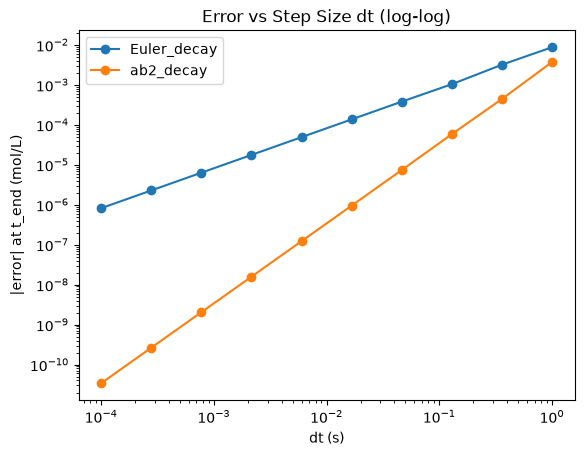

In [43]:
# YOUR CODE: convergence plot, both methods on the same axes

step_sizes = np.logspace(-4, 0, 10)

errors_Euler_decay = []
errors_ab2_decay = []
for dt in step_sizes:
    errors_Euler_decay.append(error_at_end(euler_decay, 0.1, dt, 2.0, C0=1.0))
    errors_ab2_decay.append(error_at_end(ab2_decay, 0.1, dt, 2.0, C0=1.0))

plt.loglog(step_sizes, np.abs(errors_Euler_decay), "o-", label="Euler_decay")
plt.loglog(step_sizes, np.abs(errors_ab2_decay), "o-", label="ab2_decay")
plt.xlabel("dt (s)")
plt.ylabel("|error| at t_end (mol/L)")
plt.title('Error vs Step Size dt (log-log)')
plt.legend()
plt.show()

**1c.** What is the slope of each line, and what does it tell you about each method?

## Part 2 — Where does it go unstable?

A method is **stable** here if the numerical solution decays, as the real one does.
If it grows instead, however slowly, it is unstable, and it will eventually blow up.

The helper below runs a solver for a long time (100 time constants, $t_\mathrm{end} = 100/k$) and reports whether the solution grew.

In [45]:
def is_stable(solver, k, dt):
    """Return True if solver's solution of dC/dt = -k*C decays, False if it grows.

    Runs solver(k, dt, t_end) for 100 time constants (t_end = 100/k), then
    compares |C| at the end with |C| at the start.
    """
    t_end = 100 / k
    times, C = solver(k, dt, t_end)
    return abs(C[-1]) < abs(C[0])


is_stable(euler_decay, 5, 0.1), is_stable(euler_decay, 5, 1.0)   # (True, False)

(np.True_, np.False_)

**2a.** For each of $k$ = 0.5, 2, 5 and 20 s⁻¹, find the **largest stable `dt`** for Euler and for Adams–Bashforth, to within a few percent.
Print a table with `k`, the largest stable `dt`, and the product `k * dt` for each method.

*Hint:* try a range of `dt` values, e.g. `np.linspace(0.01, 3, 300) / k`, and keep the largest one that is stable.

In [46]:
def is_stable(solver, k, dt):
    
    t_end = 100 / k
    times, C = solver(k, dt, t_end)
    return abs(C[-1]) < abs(C[0])

    
def largest_stable_dt(solver, k):
    
    dts = np.linspace(0.01, 2, 200) / k
    best = None
    for dt in dts:
        if is_stable(solver, k, dt):
            best = dt
    return best
    
k_given = [0.5, 2, 5, 20]
print(f"{'k'} {'dt_euler'} {'k*dt_euler'} {'dt_ab2'} {'k*dt_ab2'}")

for k in k_given:
    best_dt = largest_stable_dt(euler_decay,k)
    print(best_dt)
    dt_Euler = largest_stable_dt(euler_decay, k)
    dt_ab2 = largest_stable_dt(ab2_decay, k)
    print(f"{k:.2f} {dt_Euler:.5f} {k*dt_Euler:.5f} {dt_ab2:.5f} {k*dt_ab2:.5f}")



k dt_euler k*dt_euler dt_ab2 k*dt_ab2
3.98
0.50 3.98000 1.99000 2.00000 1.00000
0.995
2.00 0.99500 1.99000 0.50000 1.00000
0.398
5.00 0.39800 1.99000 0.20000 1.00000
0.0995
20.00 0.09950 1.99000 0.05000 1.00000


**2b.** For $k = 5$, plot $C(t)$ from Adams–Bashforth at a `dt` just below its stability limit and at one just above it, on the same axes, over about $0 \le t \le 10$ s.
Include the exact solution. (A linear $C$ axis is fine; you may want `plt.ylim` to keep the unstable run from hiding the others.)

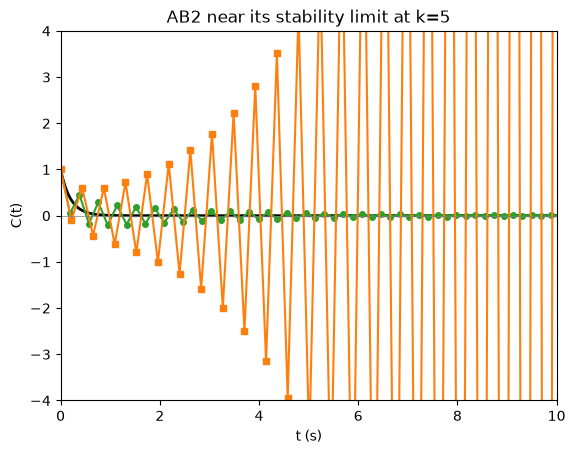

In [47]:
import numpy as np
import matplotlib.pyplot as plt

def ab2_decay(k, dt, t_end, C0=1.0):
    n = round(t_end / dt)
    times = np.arange(n + 1) * dt
    C = np.zeros(n + 1)
    C[0] = C0
    f_old = -k * C[0]
    C[1] = C[0] + dt * f_old
    for i in range(1, n):
        f_new = -k * C[i]
        C[i + 1] = C[i] + dt * (1.5 * f_new - 0.5 * f_old)
        f_old = f_new
    return times, C

k = 5.0
t_end = 10.0

# ab2 method is stable if k*dt<1.In 2A we can observe all the values of k*dt is 1. so for unstable the critical value be 1/k. 
dt_crit = 1.0 / k    

dt_below = 0.95 * dt_crit   # stable
dt_above = 1.09 * dt_crit   # unstable

t_stable, C_stable = ab2_decay(k, dt_below, t_end)
t_unstable, C_unstable = ab2_decay(k, dt_above, t_end)

t_exact = np.linspace(0, t_end, 500)
C_exact = np.exp(-k * t_exact)

plt.plot(t_exact, C_exact, 'k-', linewidth=2, label='Exact solution')
plt.plot(t_stable, C_stable, 'o-', color='tab:green', markersize=4,
          label=f'AB2, dt={dt_below:.3f} (stable, k·dt={k*dt_below:.2f})')
plt.plot(t_unstable, C_unstable, 's-', color='tab:orange', markersize=4,
          label=f'AB2, dt={dt_above:.3f} (unstable, k·dt={k*dt_above:.2f})')

plt.axhline(0, color='gray', linewidth=0.5)
plt.ylim(-4, 4)
plt.xlim(0, t_end)
plt.xlabel('t (s)')
plt.ylabel('C(t)')
plt.title(f'AB2 near its stability limit at k=5')
plt.show()

**2c.** How does the largest stable `dt` depend on $k$? State the stability limit for each method as a single number for $k\,\Delta t$.
Which method has the bigger stable range? Is that what you would have expected, given that Adams–Bashforth is the more accurate method?

## Part 3 — Why? (3b is optional)

**3a.** In words: Adams–Bashforth extrapolates the slope from the previous step. For a decaying solution, explain how that extrapolation goes wrong when the step is too large. Look closely at your unstable run in 2b: what is the solution doing from one step to the next?

**3b.** *(Optional, for a bit of maths.)* For Euler, substituting $f = -kC$ gives $C_{n+1} = (1 - k\Delta t)\, C_n$, which decays only if $|1 - k\Delta t| < 1$. Where does that put Euler's limit?

Do the same for Adams–Bashforth. You get a recurrence involving $C_{n+1}$, $C_n$ and $C_{n-1}$. Try a solution of the form $C_n = r^n$, get a quadratic for $r$, and find the value of $k\Delta t$ at which one root reaches $r = -1$. Does it match what you found in Part 2?

**Answer:**

*Your derivation here (optional). You can use LaTeX between dollar signs, e.g. `$r^2 + br + c = 0$`.*

## Part 4 — Stiff kinetics

Two first-order reactions in series, one fast and one slow:

$$ A \xrightarrow{k_1} B \xrightarrow{k_2} C, \qquad k_1 = 100\ \mathrm{s^{-1}}, \quad k_2 = 1\ \mathrm{s^{-1}} $$

$$ \frac{dC_A}{dt} = -k_1 C_A, \qquad \frac{dC_B}{dt} = k_1 C_A - k_2 C_B $$

starting from $C_A = 1$, $C_B = 0$ mol/L. The exact solution for B is
$$ C_B(t) = \frac{k_1}{k_2 - k_1}\left(e^{-k_1 t} - e^{-k_2 t}\right) $$

Now the unknown is a vector, $y = [C_A, C_B]$. The right-hand side is one function returning the vector $dy/dt$, and the solver below works for any such function. (This is the same shape `scipy.integrate.solve_ivp` uses, which we meet in Lecture 8.)

In [48]:
k1 = 100.0  # 1/s
k2 = 1.0    # 1/s


def series_rhs(y):
    """Right-hand side for A -> B -> C: return dy/dt, where y = [C_A, C_B]."""
    CA, CB = y
    return np.array([-k1 * CA, k1 * CA - k2 * CB])


def exact_CB(t):
    """Exact C_B(t) for A -> B -> C, starting from C_A = 1, C_B = 0 mol/L."""
    return k1 / (k2 - k1) * (np.exp(-k1 * t) - np.exp(-k2 * t))


def euler_system(rhs, y0, dt, t_end):
    """Solve dy/dt = rhs(y) from y(0) = y0 with Euler's method.

    rhs is a function that takes the vector y and returns the vector dy/dt.
    Returns (times, y), where y has one row per time and one column per variable.
    """
    n = round(t_end / dt)
    times = np.arange(n + 1) * dt
    y = np.zeros((n + 1, len(y0)))
    y[0] = y0
    for i in range(n):
        y[i + 1] = y[i] + dt * rhs(y[i])
    return times, y

**4a.** Write `ab2_system(rhs, y0, dt, t_end)`, the vector version of your `ab2_decay`, with the same inputs and outputs as `euler_system`.

In [49]:
def ab2_system(rhs, y0, dt, t_end):
    """Solve dy/dt = rhs(y) from y(0) = y0 with 2-step Adams-Bashforth.

    Starts with one Euler step. Same inputs and outputs as euler_system.
    """
    n = round(t_end / dt)
    times = np.arange(n + 1) * dt
    y = np.zeros((n + 1, len(y0)))
    y[0] = y0

    y[1] = y[0] + dt * rhs(y[0])
    
    for i in range(1, n):
        f_old = rhs(y[i-1])
        f_new = rhs(y[i])
        y[i + 1] = y[i] + dt * (1.5 * f_new - 0.5 * f_old)
        
    return times, y

**4b.** Solve to $t_\mathrm{end} = 5$ s with both methods at `dt` = 0.05, 0.02, 0.01 and 0.005 s. For each, print $C_B$ at $t = 5$ s next to the exact value.
Then plot $C_A(t)$ and $C_B(t)$ for one run that works, with the exact $C_B$ for comparison.

0.05 	 -1.623169741675748e+60 	 -2.781448868661164e+83
0.02 	 -1.00363 	 -2.4960664574782584e+95
0.01 	 0.00664 	 -0.32989
0.005 	 0.00672 	 0.00681
0.00681


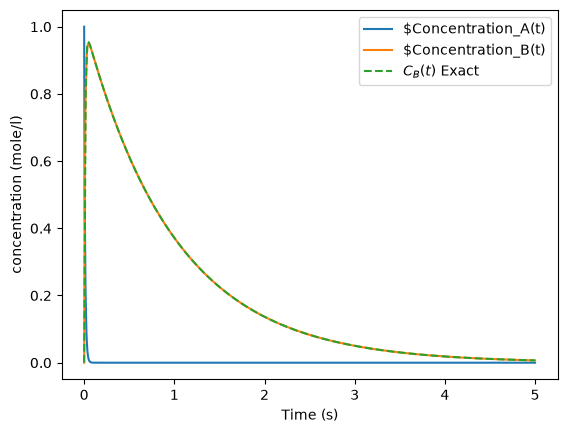

In [50]:
dt_list = [0.05, 0.02, 0.01, 0.005]
y0 = np.array([1.0, 0.0])
t_end = 5 #s
for dt in dt_list:
    t_euler, y_euler = euler_system(series_rhs, y0, dt, t_end)
    t_ab2, y_ab2 = ab2_system(series_rhs, y0, dt, t_end)

    CB_euler = y_euler[-1, 1]
    CB_ab2 = y_ab2[-1, 1]
    CB_exact = exact_CB(t_end)

    print(dt, "\t", round(CB_euler, 5), "\t", round(CB_ab2, 5))
    
print(round(CB_exact, 5))

t_1, y_1 = ab2_system(series_rhs, y0, 0.005, t_end)

CA_new = y_1[:, 0]
CB_new = y_1[:, 1]
time_new = np.linspace(0, t_end, 300)
CB_exact_new = exact_CB(time_new)

#Plot
plt.plot(t_1, CA_new, label=r"$Concentration_A(t)")
plt.plot(t_1, CB_new, label=r"$Concentration_B(t)")
plt.plot(time_new, CB_exact_new, '--', label=r"$C_B(t)$ Exact")
plt.xlabel("Time (s)")
plt.ylabel("concentration (mole/l)")
plt.legend()
plt.show()

**4c.** By about what time has A essentially all reacted? After that, $C_B$ just decays with time constant $1/k_2 = 1$ s.
So what step size would you *expect* to need to follow $C_B$ accurately, and what step size did you *actually* need to keep the solution from blowing up? Explain the difference, using what you found in Part 2.

Real reaction mechanisms can have hundreds of species with rate constants spanning ten or more orders of magnitude. What would that mean for Euler or Adams–Bashforth?

## Optional — rabbits and foxes

If you want more: use `ab2_system` on the rabbits-and-foxes model from Lecture 3 (the starter notebook is in the Ordinary Differential Equations module on Canvas), and compare its convergence with Euler's. **Entirely optional**: this assignment is long enough already, and skipping it costs nothing.

In [ ]:
# Optional